<a href="https://colab.research.google.com/github/GuiCastro7/Grupo-3---ECAA08/blob/main/Aula%2023%20-%20Protocolo%20de%20%C3%81rvore%20Geradora%20(STP%20-%20RSTP)%20-%20code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Simulação do Protocolo de Árvore Geradora (STP / RSTP) no SCADA-Core
### Linha Automatizada de Envase e Inspeção de Bebidas — Grupo 3 (ECAA08)

Este notebook modela a topologia Ethernet industrial (Camada 2 — Modbus-TCP / PROFINET) que interliga os 5 switches gerenciáveis da **Linha de Envase e Inspeção de Bebidas**:
* `SW-CORE`: Sala de Controle (`SCADA-Core`, Historiador AVL e IHM)
* `SW-SUP`: Módulo de Suprimento e Pressurização (`TS1`, `BC1`, `AS1`, `VS1`, `SP1`, `SQ1`, `SP2`)
* `SW-ENV`: Módulo de Dosagem e Envasamento (`VS2`, `SQ2`)
* `SW-CAP`: Módulo de Inspeção Óptica de Nível e Tampagem (`SL1`, `AC1`)
* `SW-INS`: Módulo de Inspeção Final de Vedação e Esteira (`VS5`, `SFC1`, `RC1`)

---
## Roteiro da Simulação
1. **Modelagem do Grafo $G = (V, E, w)$** com custos oficiais IEEE 802.1w (RSTP).
2. **Convergência RSTP (Operação Normal):** eleição do *Root Bridge*, cálculo do *Root Path Cost* e papéis de porta (*RP*, *DP*, *AP/Discarding*).
3. **Visualização Gráfica** da topologia física vs. árvore geradora lógica $T$.
4. **Simulação de Falha Física (*Link Down*):** rompimento do backbone de $10\text{ Gbps}$ (`SW-CORE` $\leftrightarrow$ `SW-SUP`) e reconvergência automática em $< 1\text{ s}$.
5. **Auditoria Matemática** comprovando que $T$ é uma Árvore Geradora ($|E_T| = |V| - 1$, conexa e acíclica).

### 1. Importação de Bibliotecas e Modelagem do Grafo da Linha de Envase
Configuramos `SW-CORE` como *Root Bridge* primário (`priority = 4096`) e `SW-SUP` como *Root Bridge* secundário (`priority = 8192`) por concentrar o maior risco hidráulico (`BC1` e `AS1`).

In [1]:
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

# ==============================================================================
# 1. DEFINIÇÃO DOS VÉRTICES (SWITCHES INDUSTRIAIS DA LINHA DE ENVASE - GRUPO 3)
# ==============================================================================
# Bridge ID (BID) = (Bridge_Priority, MAC_Address) -> Menor BID vence a eleição
switches = {
    "SW-CORE": {"setor": "Sala de Controle (SCADA-Core)",          "priority": 4096,  "mac": "00:1A:2B:00:00:01"},
    "SW-SUP":  {"setor": "Suprimento/Pressurização (TS1/BC1/AS1)", "priority": 8192,  "mac": "00:1A:2B:00:00:02"},
    "SW-ENV":  {"setor": "Dosagem e Envasamento (VS2/SQ2)",        "priority": 32768, "mac": "00:1A:2B:00:00:03"},
    "SW-CAP":  {"setor": "Inspeção Nível e Tampagem (SL1/AC1)",    "priority": 32768, "mac": "00:1A:2B:00:00:04"},
    "SW-INS":  {"setor": "Vedação e Esteira RC1 (VS5/SFC1)",       "priority": 32768, "mac": "00:1A:2B:00:00:05"},
}

# ==============================================================================
# 2. DEFINIÇÃO DAS ARESTAS (ENLACES FÍSICOS E CUSTOS IEEE 802.1w)
# ==============================================================================
# Custos padrão RSTP: 10 Gbps = 2.000 | 1 Gbps = 20.000 | 100 Mbps = 200.000
enlaces = [
    ("SW-CORE", "SW-SUP", {"cost": 2000,   "bandwidth": "10 Gbps (Fibra Backbone)"}),
    ("SW-CORE", "SW-INS", {"cost": 20000,  "bandwidth": "1 Gbps (Fibra Anel)"}),
    ("SW-SUP",  "SW-ENV", {"cost": 20000,  "bandwidth": "1 Gbps (Fibra Anel)"}),
    ("SW-ENV",  "SW-CAP", {"cost": 20000,  "bandwidth": "1 Gbps (Fibra Anel)"}),
    ("SW-CAP",  "SW-INS", {"cost": 20000,  "bandwidth": "1 Gbps (Fibra Anel)"}),
    # Enlace redundante cruzado entre Suprimento/Pressurização e Nível/Tampagem
    ("SW-SUP",  "SW-CAP", {"cost": 200000, "bandwidth": "100 Mbps (Cabo Cobre Backup)"}),
]

G = nx.Graph()
for sw, attr in switches.items():
    G.add_node(sw, **attr)
G.add_edges_from(enlaces)

print(f"Grafo da Rede SCADA-Core (Linha de Envase) criado com |V| = {G.number_of_nodes()} nós e |E| = {G.number_of_edges()} enlaces físicos.")
print(f"Ciclos independentes detectados (|E| - |V| + 1): {G.number_of_edges() - G.number_of_nodes() + 1}")

Grafo da Rede SCADA-Core (Linha de Envase) criado com |V| = 5 nós e |E| = 6 enlaces físicos.
Ciclos independentes detectados (|E| - |V| + 1): 2


### 2. Algoritmo RSTP: Eleição de Root, Cálculo de Custos e Papéis de Porta
A função `executar_rstp(grafo)` executa os 4 passos do protocolo **IEEE 802.1w**:
1. Elege o *Root Bridge* com menor `(priority, mac)`.
2. Calcula o menor *Root Path Cost* de cada switch até a raiz e define a **Root Port (RP)**.
3. Define as **Designated Ports (DP)** em cada enlace.
4. Bloqueia como **Alternate Port (AP / Discarding)** as portas que fecham ciclos.

In [2]:
def executar_rstp(grafo):
    if not nx.is_connected(grafo):
        raise ValueError("ALERTA CRÍTICO: O grafo da rede está particionado (desconexo)!")

    # Passo 1: Eleição do Root Bridge
    root_bridge = min(
        grafo.nodes,
        key=lambda n: (grafo.nodes[n]["priority"], grafo.nodes[n]["mac"])
    )

    # Passo 2: Root Path Cost mínimo e escolha da Root Port (RP)
    root_path_cost = {n: float("inf") for n in grafo.nodes}
    root_port_neighbor = {n: None for n in grafo.nodes}
    root_path_cost[root_bridge] = 0

    visitados = set()
    while len(visitados) < len(grafo.nodes):
        u = min(
            (n for n in grafo.nodes if n not in visitados),
            key=lambda n: (root_path_cost[n], grafo.nodes[n]["priority"], grafo.nodes[n]["mac"])
        )
        visitados.add(u)

        for v in grafo.neighbors(u):
            if v in visitados:
                continue
            custo_enlace = grafo.edges[u, v]["cost"]
            novo_custo = root_path_cost[u] + custo_enlace

            atual_pai = root_port_neighbor[v]
            bid_u = (grafo.nodes[u]["priority"], grafo.nodes[u]["mac"])
            bid_atual = (grafo.nodes[atual_pai]["priority"], grafo.nodes[atual_pai]["mac"]) if atual_pai else (float("inf"), "")

            if (novo_custo < root_path_cost[v]) or (novo_custo == root_path_cost[v] and bid_u < bid_atual):
                root_path_cost[v] = novo_custo
                root_port_neighbor[v] = u

    # Passo 3 e 4: Papéis e estados de porta
    arestas_ativas = []
    arestas_bloqueadas = []
    tabela_portas = []

    for u, v, data in grafo.edges(data=True):
        if root_port_neighbor[v] == u:
            papel_u, estado_u = "Designated Port (DP)", "Forwarding"
            papel_v, estado_v = "Root Port (RP)", "Forwarding"
            arestas_ativas.append((u, v))
        elif root_port_neighbor[u] == v:
            papel_u, estado_u = "Root Port (RP)", "Forwarding"
            papel_v, estado_v = "Designated Port (DP)", "Forwarding"
            arestas_ativas.append((u, v))
        else:
            criterio_u = (root_path_cost[u], grafo.nodes[u]["priority"], grafo.nodes[u]["mac"])
            criterio_v = (root_path_cost[v], grafo.nodes[v]["priority"], grafo.nodes[v]["mac"])

            if criterio_u < criterio_v:
                papel_u, estado_u = "Designated Port (DP)", "Forwarding"
                papel_v, estado_v = "Alternate Port (AP)", "Discarding (Bloqueada)"
            else:
                papel_u, estado_u = "Alternate Port (AP)", "Discarding (Bloqueada)"
                papel_v, estado_v = "Designated Port (DP)", "Forwarding"
            arestas_bloqueadas.append((u, v))

        tabela_portas.append({
            "Enlace": f"{u} <--> {v}",
            "Custo": data["cost"],
            "Porta Origem": f"{u}: {papel_u} [{estado_u}]",
            "Porta Destino": f"{v}: {papel_v} [{estado_v}]",
            "Status Enlace": "ATIVO (Árvore T)" if (u, v) in arestas_ativas else "BLOQUEADO (Loop Prevention)"
        })

    return root_bridge, root_path_cost, arestas_ativas, arestas_bloqueadas, pd.DataFrame(tabela_portas)

root, custos, ativas, bloqueadas, df_rstp = executar_rstp(G)

print("=== RESULTADO DA CONVERGÊNCIA RSTP (OPERAÇÃO NORMAL) ===")
print(f"Root Bridge Eleito: {root} (Priority: {G.nodes[root]['priority']}, MAC: {G.nodes[root]['mac']})\n")
print("Custo de Caminho até o Root Bridge por Módulo:")
for sw, c in custos.items():
    print(f"  - {sw:8s} ({G.nodes[sw]['setor']:39s}): Custo = {c}")

print("\nTabela de Estados das Portas:")
df_rstp

=== RESULTADO DA CONVERGÊNCIA RSTP (OPERAÇÃO NORMAL) ===
Root Bridge Eleito: SW-CORE (Priority: 4096, MAC: 00:1A:2B:00:00:01)

Custo de Caminho até o Root Bridge por Módulo:
  - SW-CORE  (Sala de Controle (SCADA-Core)          ): Custo = 0
  - SW-SUP   (Suprimento/Pressurização (TS1/BC1/AS1) ): Custo = 2000
  - SW-ENV   (Dosagem e Envasamento (VS2/SQ2)        ): Custo = 22000
  - SW-CAP   (Inspeção Nível e Tampagem (SL1/AC1)    ): Custo = 40000
  - SW-INS   (Vedação e Esteira RC1 (VS5/SFC1)       ): Custo = 20000

Tabela de Estados das Portas:


,Enlace,Custo,Porta Origem,Porta Destino,Status Enlace
0,SW-CORE <--> SW-SUP,2000,SW-CORE: Designated Port (DP) [Forwarding],SW-SUP: Root Port (RP) [Forwarding],ATIVO (Árvore T)
1,SW-CORE <--> SW-INS,20000,SW-CORE: Designated Port (DP) [Forwarding],SW-INS: Root Port (RP) [Forwarding],ATIVO (Árvore T)
2,SW-SUP <--> SW-ENV,20000,SW-SUP: Designated Port (DP) [Forwarding],SW-ENV: Root Port (RP) [Forwarding],ATIVO (Árvore T)
3,SW-SUP <--> SW-CAP,200000,SW-SUP: Designated Port (DP) [Forwarding],SW-CAP: Alternate Port (AP) [Discarding (Bloqu...,BLOQUEADO (Loop Prevention)
4,SW-ENV <--> SW-CAP,20000,SW-ENV: Designated Port (DP) [Forwarding],SW-CAP: Alternate Port (AP) [Discarding (Bloqu...,BLOQUEADO (Loop Prevention)
5,SW-CAP <--> SW-INS,20000,SW-CAP: Root Port (RP) [Forwarding],SW-INS: Designated Port (DP) [Forwarding],ATIVO (Árvore T)


### 3. Visualização Gráfica: Topologia Física vs. Árvore Geradora Lógica
* **Nó Dourado:** *Root Bridge* (`SW-CORE`).
* **Arestas Verdes Contínuas:** Enlaces ativos na Árvore Geradora $T$ (*Forwarding*).
* **Arestas Vermelhas Tracejadas:** Enlaces em *Discarding* (bloqueados logicamente para evitar *loops*).

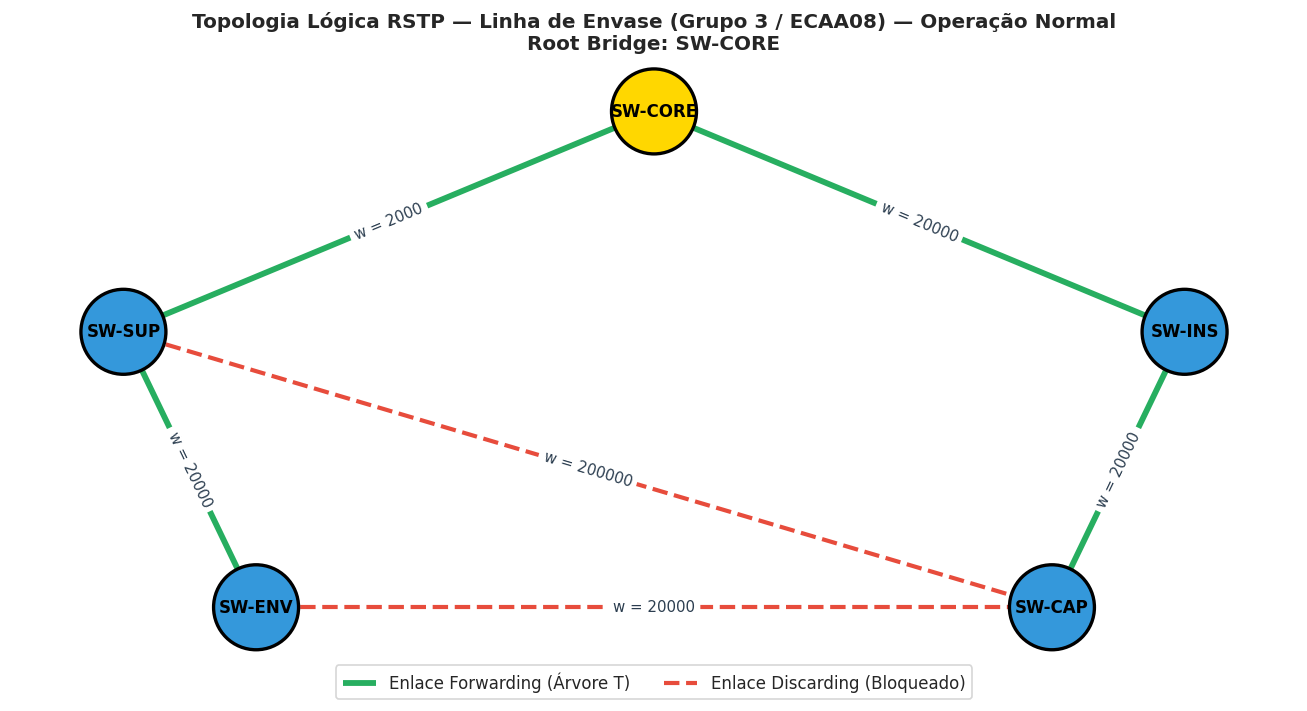

In [3]:
def plotar_topologia_rstp(grafo, root, ativas, bloqueadas, titulo_extra="Operação Normal"):
    pos = {
        "SW-CORE": (0.5, 1.0),
        "SW-SUP":  (0.1, 0.6),
        "SW-INS":  (0.9, 0.6),
        "SW-ENV":  (0.2, 0.1),
        "SW-CAP":  (0.8, 0.1),
    }

    fig, ax = plt.subplots(figsize=(11, 6))

    node_colors = ["#FFD700" if n == root else "#3498DB" for n in grafo.nodes]
    nx.draw_networkx_nodes(grafo, pos, node_color=node_colors, node_size=2600, edgecolors="black", linewidths=2, ax=ax)
    nx.draw_networkx_labels(grafo, pos, font_size=10, font_weight="bold", ax=ax)

    nx.draw_networkx_edges(grafo, pos, edgelist=ativas, width=3.5, edge_color="#27AE60", ax=ax, label="Enlace Forwarding (Árvore T)")
    nx.draw_networkx_edges(grafo, pos, edgelist=bloqueadas, width=2.5, edge_color="#E74C3C", style="dashed", ax=ax, label="Enlace Discarding (Bloqueado)")

    edge_labels = {(u, v): f"w = {d['cost']}" for u, v, d in grafo.edges(data=True)}
    nx.draw_networkx_edge_labels(grafo, pos, edge_labels=edge_labels, font_size=9, font_color="#2C3E50", ax=ax)

    ax.set_title(f"Topologia Lógica RSTP — Linha de Envase (Grupo 3 / ECAA08) — {titulo_extra}\nRoot Bridge: {root}", fontsize=12, fontweight="bold")
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.08), ncol=2, frameon=True)
    ax.axis("off")
    plt.tight_layout()
    plt.show()

plotar_topologia_rstp(G, root, ativas, bloqueadas, "Operação Normal")

### 4. Simulação de Falha Crítica (Rompimento do Backbone `SW-CORE` $\leftrightarrow$ `SW-SUP`)
Simulamos o rompimento físico da fibra de $10\text{ Gbps}$ entre `SW-CORE` e `SW-SUP`. O RSTP promove automaticamente a porta *Alternate* entre `SW-ENV` e `SW-CAP` para *Forwarding*, restabelecendo a comunicação com `TS1`/`BC1`/`AS1` sem perda de supervisão.

⚠️ SIMULAÇÃO DE FALHA: Rompimento físico do enlace SW-CORE <--> SW-SUP!

Novos Custos de Caminho após Reconvergência RSTP (< 1 segundo):
  - SW-CORE : Novo Custo = 0 (Anterior: 0)
  - SW-SUP  : Novo Custo = 80000 (Anterior: 2000)
  - SW-ENV  : Novo Custo = 60000 (Anterior: 22000)
  - SW-CAP  : Novo Custo = 40000 (Anterior: 40000)
  - SW-INS  : Novo Custo = 20000 (Anterior: 20000)


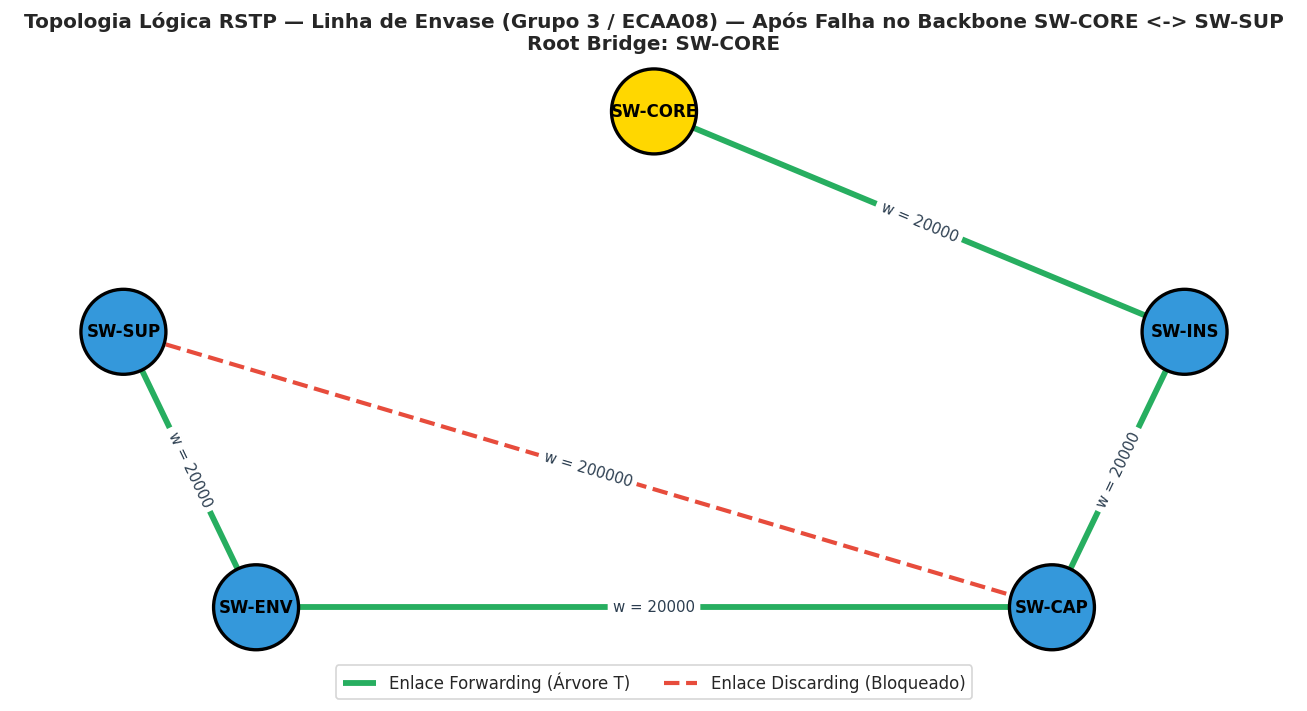

,Enlace,Custo,Porta Origem,Porta Destino,Status Enlace
0,SW-CORE <--> SW-INS,20000,SW-CORE: Designated Port (DP) [Forwarding],SW-INS: Root Port (RP) [Forwarding],ATIVO (Árvore T)
1,SW-SUP <--> SW-ENV,20000,SW-SUP: Root Port (RP) [Forwarding],SW-ENV: Designated Port (DP) [Forwarding],ATIVO (Árvore T)
2,SW-SUP <--> SW-CAP,200000,SW-SUP: Alternate Port (AP) [Discarding (Bloqu...,SW-CAP: Designated Port (DP) [Forwarding],BLOQUEADO (Loop Prevention)
3,SW-ENV <--> SW-CAP,20000,SW-ENV: Root Port (RP) [Forwarding],SW-CAP: Designated Port (DP) [Forwarding],ATIVO (Árvore T)
4,SW-CAP <--> SW-INS,20000,SW-CAP: Root Port (RP) [Forwarding],SW-INS: Designated Port (DP) [Forwarding],ATIVO (Árvore T)


In [4]:
G_falha = G.copy()
enlace_rompido = ("SW-CORE", "SW-SUP")
G_falha.remove_edge(*enlace_rompido)

print(f"⚠️ SIMULAÇÃO DE FALHA: Rompimento físico do enlace {enlace_rompido[0]} <--> {enlace_rompido[1]}!")

root_f, custos_f, ativas_f, bloqueadas_f, df_rstp_f = executar_rstp(G_falha)

print("\nNovos Custos de Caminho após Reconvergência RSTP (< 1 segundo):")
for sw, c in custos_f.items():
    print(f"  - {sw:8s}: Novo Custo = {c} (Anterior: {custos[sw]})")

plotar_topologia_rstp(G_falha, root_f, ativas_f, bloqueadas_f, "Após Falha no Backbone SW-CORE <-> SW-SUP")
df_rstp_f

### 5. Auditoria Matemática do Subgrafo Resultante $T$
Verificamos formalmente que o subgrafo ativo $T = (V, E_{\text{ativas}})$ após a falha continua sendo uma **Árvore Geradora**:
1. Todos os 5 módulos permanecem conectados ($V_T = V_G$).
2. Número exato de arestas ativas: $|E_T| = |V_T| - 1 = 4$.
3. Grafo **conexo** e **acíclico** (zero *Broadcast Storms*).

In [5]:
def auditar_arvore_geradora(grafo_original, arestas_ativas):
    T = nx.Graph()
    T.add_nodes_from(grafo_original.nodes(data=True))
    T.add_edges_from(arestas_ativas)

    n_vertices = T.number_of_nodes()
    n_arestas = T.number_of_edges()
    conexo = nx.is_connected(T)
    aciclico = nx.is_forest(T) and conexo
    e_arvore = nx.is_tree(T)

    print("=== AUDITORIA MATEMÁTICA DO SUBGRAFO LÓGICO T ===")
    print(f"1. Vértices preservados (|V_T| == |V_G|): {n_vertices == grafo_original.number_of_nodes()} ({n_vertices} nós)")
    print(f"2. Propriedade |E_T| = |V_T| - 1:          {n_arestas == n_vertices - 1} ({n_arestas} arestas ativas)")
    print(f"3. Grafo Conexo (Todos módulos alcançáveis): {conexo}")
    print(f"4. Grafo Acíclico (Zero Broadcast Storms):   {aciclico}")
    print(f"5. Resultado Formal (T é Árvore Geradora?):  {e_arvore}")

auditar_arvore_geradora(G_falha, ativas_f)

=== AUDITORIA MATEMÁTICA DO SUBGRAFO LÓGICO T ===
1. Vértices preservados (|V_T| == |V_G|): True (5 nós)
2. Propriedade |E_T| = |V_T| - 1:          True (4 arestas ativas)
3. Grafo Conexo (Todos módulos alcançáveis): True
4. Grafo Acíclico (Zero Broadcast Storms):   True
5. Resultado Formal (T é Árvore Geradora?):  True
